# Unit 3 — Multimedia and Interactive Visualization (UE24CS342AA9)
## Activity Notebook: The Tumour-Board Briefing

### Scenario

You are the visualization engineer in the **3-D Imaging Lab at City General Hospital**. Tomorrow morning the
neuro-oncology **tumour board** (a neurosurgeon, a radiologist and an oncologist) will review a patient's head CT
(`unit3_ppt3_head_ct_phantom.csv`). The lab head forwards you four requests:

1. **IT department:** *"The new scanner protocol is 512 × 512 × 300 at 0.5 × 0.5 × 1.0 mm. How much storage per scan,
   and how many samples does one volume-rendered frame cost?"*
2. **Radiologist:** *"Show me the lesion in all three planes, at its centre, with the anatomy undistorted."*
3. **Neurosurgeon:** *"I need the tumour volume in mL — and I want to know how much that number depends on the
   threshold you picked."*
4. **Oncologist:** *"Your last 3-D render showed a beautiful skull and nothing else. I need to see the tumour and its
   relation to the ventricles."*

Cells marked **`# TODO`** are for you to complete. Markdown cells marked **Reflection** are for you to answer in your
own words. The ground-truth `labels` array may be used **only to evaluate** your results, never to find the tumour.

## Part 0 — Setup (given)

Run this cell as-is. It loads the volume `vol[z, y, x]`, the evaluation-only `labels`, the voxel spacing, and two
helpers: `make_tf(points)` builds a transfer function from `(hu, (r, g, b), alpha)` control points, and
`render(volume, tf, axis)` ray-casts the volume with front-to-back compositing (resampled at 2× density).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import ndimage

np.random.seed(0)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

ct = pd.read_csv("unit3_ppt3_head_ct_phantom.csv")
NZ, NY, NX = ct.z.max() + 1, ct.y.max() + 1, ct.x.max() + 1
vol = ct.intensity_hu.values.reshape(NZ, NY, NX)        # V[z, y, x]  (z = feet->head, y = front->back, x = left->right)
labels = ct.label.values.reshape(NZ, NY, NX)            # ground truth: 0 air, 1 scalp, 2 bone, 3 brain, 4 CSF, 5 tumour
SPACING = (4.0, 3.0, 3.0)                               # voxel size in mm along (z, y, x)
VOXEL_MM3 = np.prod(SPACING)
ASPECT = SPACING[0] / SPACING[2]                        # use when z is on a screen axis

def make_tf(points):
    # points: list of (hu, (r, g, b), alpha) control points -> transfer function T(s) -> (C, alpha)
    hu = np.array([p[0] for p in points], float)
    rgb = np.array([p[1] for p in points], float)
    alpha = np.array([p[2] for p in points], float)
    def tf(s):
        c = np.stack([np.interp(s, hu, rgb[:, k]) for k in range(3)], axis=-1)
        return c, np.interp(s, hu, alpha)
    return tf

def render(volume, tf, axis=1, upsample=2):
    # Orthographic ray casting with front-to-back compositing; rays travel along `axis`.
    # upsample=2 resamples the volume trilinearly at twice the density (smoother, fewer aliasing artifacts).
    v = ndimage.zoom(volume.astype(float), upsample, order=1) if upsample > 1 else volume
    v = np.moveaxis(v, axis, 0)
    C = np.zeros(v.shape[1:] + (3,)); A = np.zeros(v.shape[1:])
    for sample in v:                                    # one sample per voxel step along every ray at once
        c, a = tf(sample)
        C += ((1 - A) * a)[..., None] * c
        A += (1 - A) * a
    return C, A

print(f"vol {vol.shape} (z, y, x), voxel {SPACING} mm, {VOXEL_MM3:.0f} mm^3 per voxel")

vol (48, 64, 64) (z, y, x), voxel (4.0, 3.0, 3.0) mm, 36 mm^3 per voxel


## Task 1 — The IT Department's Numbers (Request #1)

**Real-world usage:** PACS storage and GPU sizing for 3-D workstations are budgeted from exactly these figures.

**Why this technique:** Voxel count = Nx·Ny·Nz (Slides 7, 12); each ray samples the volume at successive positions
(Slide 22), so one frame costs ≈ rays × samples per ray; early ray termination skips samples once α_acc → 1
(Slide 27).

**TODO:**
1. Number of voxels in a 512 × 512 × 300 scan, and its size in MB at 16 bits per voxel.
2. Physical size of the scanned region in mm, and the volume of one voxel in mm³ (0.5 × 0.5 × 1.0 mm).
3. Samples needed for ONE front-view rendered frame (one ray per x–z pixel, one sample per voxel step in y), and
   for a 360° rotation video of 120 frames.
4. If early ray termination stops rays after 35% of their samples on average, how many samples does the 120-frame
   video need instead?

In [2]:
# TODO 1
n_voxels = 512 * 512 * 300
scan_mb = n_voxels * 2 / 1_000_000  # decimal MB; 16 bits = 2 bytes

# TODO 2
extent_mm = (512 * 0.5, 512 * 0.5, 300 * 1.0)  # (x, y, z) in mm
voxel_mm3 = 0.5 * 0.5 * 1.0

# TODO 3
samples_per_frame = 512 * 300 * 512  # x-z pixels/rays, each with 512 y samples
samples_video = samples_per_frame * 120

# TODO 4
samples_video_ert = samples_video * (1 - 0.35)

print(f"{n_voxels:,} voxels = {scan_mb:.1f} MB | extent {extent_mm} mm | voxel {voxel_mm3} mm^3")
print(f"samples/frame {samples_per_frame:,} | 120 frames {samples_video:,} | with early termination {samples_video_ert:,.0f}")

78,643,200 voxels = 157.3 MB | extent (256.0, 256.0, 300.0) mm | voxel 0.25 mm^3
samples/frame 78,643,200 | 120 frames 9,437,184,000 | with early termination 6,134,169,600


**Reflection — Answer:**

If anisotropic voxels were treated as if they were all the same size, distances and shapes would be distorted in coronal and sagittal views. The 1.0 mm spacing along z is twice the 0.5 mm spacing in x and y, so ignoring spacing would stretch or compress anatomy and make measurements inaccurate. Resampling or displaying slices with the correct voxel aspect ratio preserves the physical proportions.

## Task 2 — Find the Lesion and Show It in Three Planes (Request #2)

**Real-world usage:** Every radiology workstation opens on a 3-plane MPR with linked cross-hairs.

**Why this technique:** **Orthogonal slices / MPR** give complementary views of the same structure (Slides 15–17);
a **window/level** setting is the slice-display transfer function; the correct **voxel aspect ratio** keeps anatomy
undistorted (Slide 9).

**TODO:**
1. Find the lesion *without* `labels`: take voxels with 55 < HU < 90 that lie **inside the brain** — use
   `inside = ndimage.binary_fill_holes(vol > 300) & ~(vol > 300)` and erode it 3 times
   (`ndimage.binary_erosion(..., iterations=3)`) to avoid the partial-volume shell under the skull.
2. Keep the largest connected component (`ndimage.label`) and compute its centroid (z, y, x) as integers.
3. Plot axial, coronal and sagittal slices through that centroid with cross-hairs, a brain window (W = 80, L = 40),
   and `aspect=ASPECT` for the two views that contain z.
4. Evaluation only: print how far (in mm) your centroid is from the centroid of `labels == 5`.

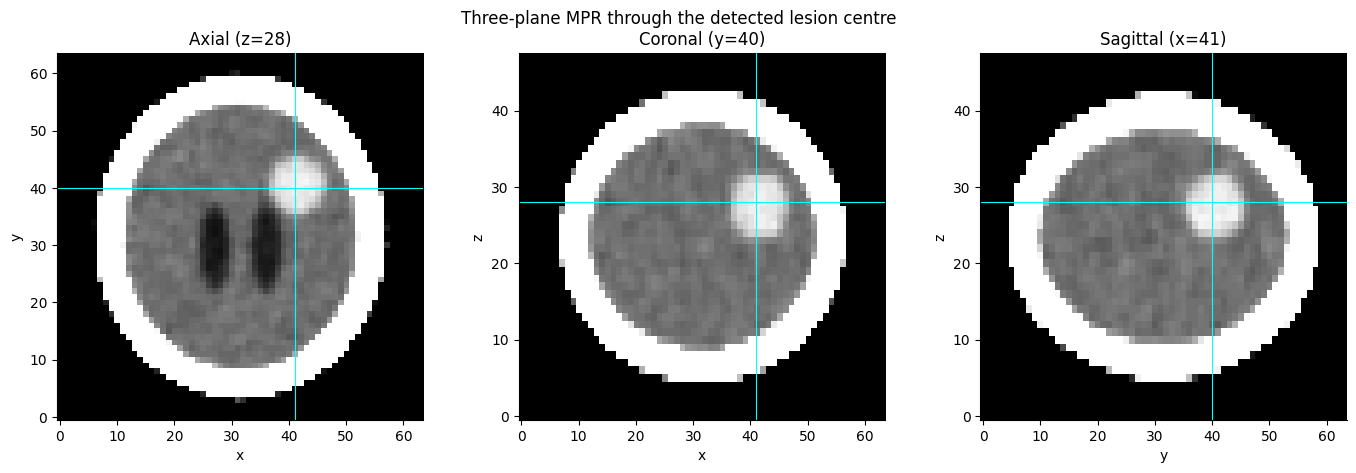

Detected centre (z, y, x) = (28, 40, 41)
Evaluation-only distance from ground-truth tumour centroid: 2.92 mm


In [3]:
def window(a, W, L):
    return np.clip((a - (L - W / 2)) / W, 0, 1)

# TODO 1: identify candidates using intensity and an eroded interior mask (do not use labels)
inside = ndimage.binary_fill_holes(vol > 300) & ~(vol > 300)
inside = ndimage.binary_erosion(inside, iterations=3)
candidates = (vol > 55) & (vol < 90) & inside

# TODO 2: keep the largest connected component and calculate its integer centroid
components, n_components = ndimage.label(candidates)
component_sizes = np.bincount(components.ravel())
component_sizes[0] = 0
largest_component = int(np.argmax(component_sizes))
lesion = components == largest_component
cz, cy, cx = (int(round(v)) for v in ndimage.center_of_mass(lesion))

# TODO 3: axial, coronal and sagittal MPR slices through the centroid
fig, axes = plt.subplots(1, 3, figsize=(14, 4.6))
axes[0].imshow(window(vol[cz, :, :], 80, 40), cmap="gray", origin="lower")
axes[0].axhline(cy, color="cyan", linewidth=0.8); axes[0].axvline(cx, color="cyan", linewidth=0.8)
axes[0].set_title(f"Axial (z={cz})"); axes[0].set_xlabel("x"); axes[0].set_ylabel("y")

axes[1].imshow(window(vol[:, cy, :], 80, 40), cmap="gray", origin="lower", aspect=ASPECT)
axes[1].axhline(cz, color="cyan", linewidth=0.8); axes[1].axvline(cx, color="cyan", linewidth=0.8)
axes[1].set_title(f"Coronal (y={cy})"); axes[1].set_xlabel("x"); axes[1].set_ylabel("z")

axes[2].imshow(window(vol[:, :, cx], 80, 40), cmap="gray", origin="lower", aspect=ASPECT)
axes[2].axhline(cz, color="cyan", linewidth=0.8); axes[2].axvline(cy, color="cyan", linewidth=0.8)
axes[2].set_title(f"Sagittal (x={cx})"); axes[2].set_xlabel("y"); axes[2].set_ylabel("z")

fig.suptitle("Three-plane MPR through the detected lesion centre")
plt.tight_layout(); plt.show()

# TODO 4 (evaluation only): compare to ground truth after detection
truth_centroid = np.array(ndimage.center_of_mass(labels == 5))
detected_centroid = np.array([cz, cy, cx], dtype=float)
distance_mm = np.linalg.norm((detected_centroid - truth_centroid) * np.array(SPACING))
print(f"Detected centre (z, y, x) = ({cz}, {cy}, {cx})")
print(f"Evaluation-only distance from ground-truth tumour centroid: {distance_mm:.2f} mm")

**Reflection — Answer:**

The erosion step removes the thin inner boundary around the skull, where a voxel can contain a mixture of bone and soft tissue because of the partial-volume effect. Those mixed voxels can have intensities that overlap the tumour's range, so they may be falsely included by an intensity-only transfer function or threshold. Eroding the interior mask reduces these boundary candidates and makes the connected component more likely to represent the lesion.

## Task 3 — Tumour Volume and Its Threshold Sensitivity (Request #3)

**Real-world usage:** Tumour volume drives treatment decisions and response assessment, so its uncertainty must be
reported.

**Why this technique:** An **isosurface/segmentation at threshold c** defines the structure — and *the chosen c
strongly influences the resulting geometry* (Slides 19–20, 31–32).

**TODO:**
1. For c in `[45, 50, 55, 60, 65, 70]`, grow the region `vol > c` from your lesion centre (connected component
   containing `(cz, cy, cx)`).
2. For each c, record the voxel count, the volume in mL (`voxels * VOXEL_MM3 / 1000`), and — evaluation only — the
   Dice overlap with `labels == 5`.
3. Plot volume (mL) vs. threshold, and mark the threshold with the best Dice.
4. Print the range of volumes you would report to the surgeon.

,Threshold (HU),Voxels,Volume (mL),Dice (evaluation only)
0,45,535,19.260,0.928929
1,50,464,16.704,0.993534
2,55,431,15.516,0.963128
3,60,350,12.600,0.859951
4,65,273,9.828,0.740841
5,70,170,6.120,0.536278


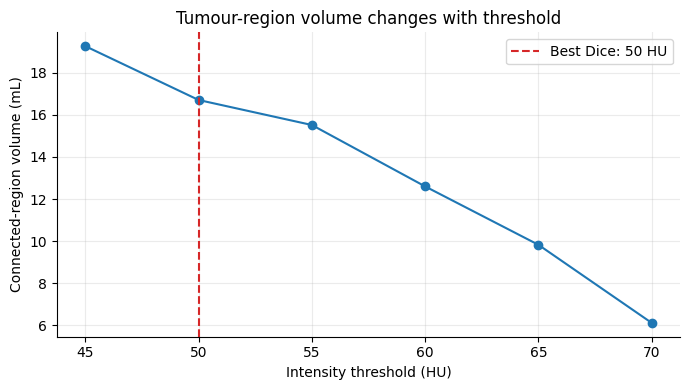

Across the tested thresholds, connected-region volume ranges from 6.12 to 19.26 mL.
Best Dice among these thresholds occurs at 50 HU (evaluation only).


In [4]:
truth = labels == 5
rows = []

# TODO 1 & 2: threshold the CT volume and keep the connected region containing the detected centre
for c in [45, 50, 55, 60, 65, 70]:
    mask = vol > c
    components, _ = ndimage.label(mask)
    seed_component = components[cz, cy, cx]
    region = (components == seed_component) if seed_component != 0 else np.zeros_like(mask, dtype=bool)
    count = int(region.sum())
    volume_ml = count * VOXEL_MM3 / 1000
    intersection = np.logical_and(region, truth).sum()
    denom = region.sum() + truth.sum()
    dice = (2 * intersection / denom) if denom else 0.0
    rows.append({"Threshold (HU)": c, "Voxels": count, "Volume (mL)": volume_ml, "Dice (evaluation only)": dice})

table = pd.DataFrame(rows)
display(table)

# TODO 3: plot volume versus threshold and mark the best-Dice threshold
best_idx = int(table["Dice (evaluation only)"].idxmax())
best_threshold = int(table.loc[best_idx, "Threshold (HU)"])
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(table["Threshold (HU)"], table["Volume (mL)"], marker="o")
ax.axvline(best_threshold, color="tab:red", linestyle="--", label=f"Best Dice: {best_threshold} HU")
ax.set_xlabel("Intensity threshold (HU)")
ax.set_ylabel("Connected-region volume (mL)")
ax.set_title("Tumour-region volume changes with threshold")
ax.grid(True, alpha=0.25)
ax.legend()

plt.tight_layout(); plt.show()

# TODO 4: report the observed range, noting that this threshold-grown region may include connected anatomy
volume_min = table["Volume (mL)"].min()
volume_max = table["Volume (mL)"].max()
print(f"Across the tested thresholds, connected-region volume ranges from {volume_min:.2f} to {volume_max:.2f} mL.")
print(f"Best Dice among these thresholds occurs at {best_threshold} HU (evaluation only).")

**Reflection — Answer:**

Without ground truth, I would select a threshold based on the CT intensity distribution, radiologist review of the lesion boundary in all three planes, and whether the segmentation is anatomically plausible. I would compare several reasonable thresholds rather than treating one as exact, and ask the radiologist to approve the final contour. I would show a volume-versus-threshold plot and report a range of plausible volumes alongside the chosen value. The Dice score is available here only because this is a phantom dataset with evaluation labels; it would not be available in a real patient scan.

## Task 4 — A 3-D Render That Shows the Tumour (Request #4)

**Real-world usage:** Pre-operative 3-D views show a lesion in context with critical structures (here the ventricles).

**Why this technique:** **Direct volume rendering** with a designed **transfer function** — colour to *identify*
materials, opacity to *reveal or suppress* them (Slides 21–27); occlusion is the main enemy (Slide 28).

**TODO:**
1. Render the given `bone_tf` (front view, `axis=1`) — this is the "beautiful skull" the oncologist complained about.
2. Design your own `tumour_tf` with `make_tf([...])` so that: air and soft tissue are fully transparent, bone is
   *almost* transparent (α ≤ 0.01, still gives context), CSF (≈ 5–20 HU) is blue and faint, and the tumour range
   is red. Remember that opacity **accumulates over every sample along a ray**: a thick structure with α ≈ 0.1
   per sample becomes nearly opaque, while a thin one stays faint — use that to your advantage.
3. Render your TF from the front (`axis=1`) **and** from above (`axis=0`), side by side with the bone render.
4. Give the figure a conclusion-style title.

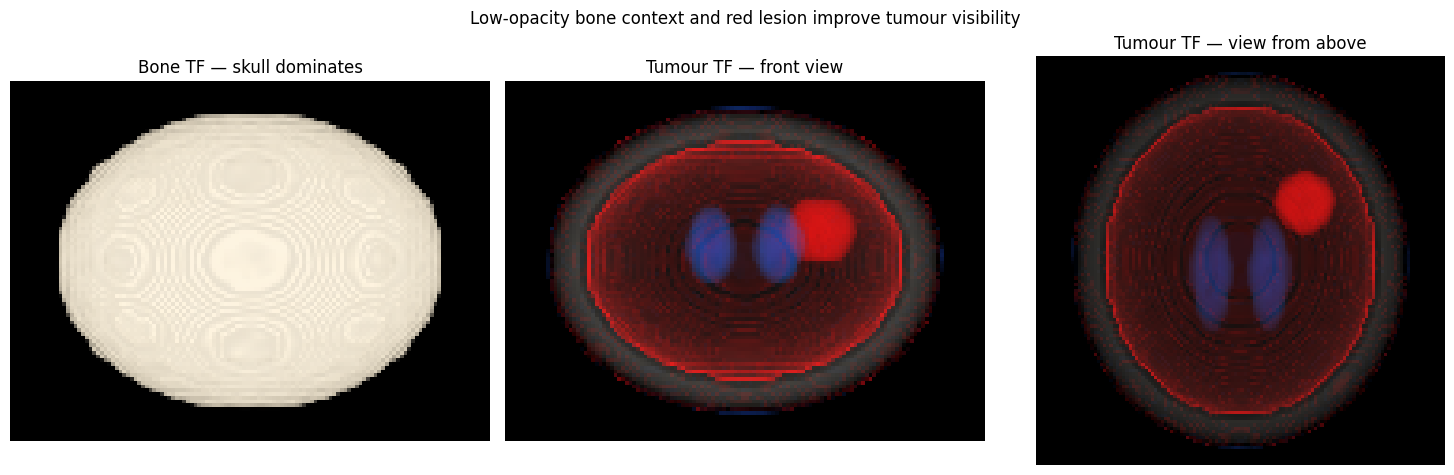

In [5]:
bone_tf = make_tf([(-1000, (0, 0, 0), 0), (200, (0, 0, 0), 0), (400, (1, 0.95, 0.85), 0.3), (1500, (1, 1, 1), 0.6)])

# TODO 2: make air/soft tissue transparent, bone nearly transparent, CSF faint blue, tumour red
tumour_tf = make_tf([
    (-1100, (0, 0, 0), 0.0),
    (-200,  (0, 0, 0), 0.0),
    (0,     (0, 0, 0), 0.0),
    (4,     (0.15, 0.35, 1.0), 0.0),
    (8,     (0.15, 0.35, 1.0), 0.025),
    (20,    (0.15, 0.45, 1.0), 0.025),
    (30,    (0, 0, 0), 0.0),
    (45,    (0, 0, 0), 0.0),
    (55,    (1.0, 0.05, 0.05), 0.07),
    (70,    (1.0, 0.05, 0.05), 0.09),
    (90,    (1.0, 0.05, 0.05), 0.0),
    (200,   (0, 0, 0), 0.0),
    (400,   (1.0, 0.95, 0.85), 0.005),
    (1000,  (1.0, 1.0, 1.0), 0.005)
])

fig, axes = plt.subplots(1, 3, figsize=(15, 4.8))

# TODO 1 & 3: bone render, tumour TF front view, and tumour TF top view
bone_rgb, bone_alpha = render(vol, bone_tf, axis=1)
front_rgb, front_alpha = render(vol, tumour_tf, axis=1)
top_rgb, top_alpha = render(vol, tumour_tf, axis=0)
axes[0].imshow(np.clip(bone_rgb, 0, 1), origin="lower")
axes[0].set_title("Bone TF — skull dominates")
axes[1].imshow(np.clip(front_rgb, 0, 1), origin="lower")
axes[1].set_title("Tumour TF — front view")
axes[2].imshow(np.clip(top_rgb, 0, 1), origin="lower")
axes[2].set_title("Tumour TF — view from above")
for ax in axes:
    ax.set_axis_off()

# TODO 4: conclusion-style title
fig.suptitle("Low-opacity bone context and red lesion improve tumour visibility")
plt.tight_layout(); plt.show()

**Reflection — Answer:**

The faint red rim is caused by occlusion and overlapping intensity ranges: voxels near the skull can have intensities that overlap the target range, and opacity accumulates along each viewing ray. A segmentation mask or isosurface based on a carefully chosen threshold can restrict the red rendering to the connected lesion region and remove much of the rim. A transfer function alone maps intensity to colour and opacity; it cannot distinguish two different tissues that have the same intensity.

**Final note to the tumour board:**

The detected lesion is toward the right side and posterior half of this phantom scan, centred near voxel (z=28, y=40, x=41). Across the six tested thresholds, the connected-region volume ranges from **6.12 to 19.26 mL**; this is a threshold-sensitivity range, not a definitive clinical measurement, because lower thresholds can include connected neighbouring tissue. I recommend opening with the **three-plane MPR**, because slicing exposes internal structure and lets the team inspect the lesion boundary in axial, coronal and sagittal views without 3-D occlusion. The threshold-volume plot should be reviewed alongside those images so the surgeon can see how the segmentation choice affects the measurement. The 3-D render is useful for showing context, but opacity accumulation can hide structures behind nearer tissue. Finally, overlapping intensity ranges mean a transfer function can colour some non-tumour voxels similarly to the lesion.